In [ ]:
import os
import numpy as np
import pandas as pd
from scipy.signal import hilbert

# ==========================================
# 1. KONFIGURASI & MAPPING CHANNEL
# ==========================================
CHANNEL_NAMES = {
    0: "Fp1",
    1: "Fp2",
    2: "F3",
    3: "F4",
    4: "C3",
    5: "C4",
    6: "O1",
    7: "O2",
}


def get_plv_feature_names(channel_map):
    names = []
    n_ch = len(channel_map)
    for i in range(n_ch):
        for j in range(i + 1, n_ch):
            names.append(f"{channel_map[i]}-{channel_map[j]}")
    return names


# Generate nama kolom fitur satu kali di awal
PLV_FEATURE_NAMES = get_plv_feature_names(CHANNEL_NAMES)


# ==========================================
# 2. FUNGSI INTI KOMPUTASI PLV
# ==========================================
def compute_plv_window(window_data):
    """Menghitung sinkronisasi fase antar channel menggunakan Hilbert Transform.

    window_data : np.array [n_channels, n_samples]
    """
    window_data = np.asarray(window_data, dtype=float)
    n_ch, _ = window_data.shape

    # Transformasi Hilbert untuk mendapatkan fase instan
    analytic = hilbert(window_data, axis=1)
    phase = np.angle(analytic)

    plv_vals = []
    for i in range(n_ch):
        for j in range(i + 1, n_ch):
            # Rumus PLV: |1/N * sum(exp(i * (phase_i - phase_j)))|
            diff = phase[i] - phase[j]
            plv = np.abs(np.mean(np.exp(1j * diff)))
            plv_vals.append(plv)

    return np.array(plv_vals, dtype=np.float32)


# ==========================================
# 3. PROSES EKSTRAKSI PER FILE (MODIFIKASI VV)
# ==========================================
def process_eeg_plv(input_folder, output_folder):
    if not os.path.exists(output_folder):
        os.makedirs(output_folder)

    files = sorted([f for f in os.listdir(input_folder) if f.endswith(".csv")])
    print(
        f"🚀 Memulai ekstraksi PLV (verbal-visual). Ditemukan {len(files)} file."
    )

    # Kolom datapoint (asumsi 250Hz per window)
    dp_cols = [f"datapoint{i}" for i in range(1, 251)]

    for i, fname in enumerate(files, start=1):
        # DETEKSI LABEL: Mengubah logika untuk mencari kata 'verbal' atau 'visual'
        if "verbal" in fname.lower():
            current_label = "verbal"
        elif "visual" in fname.lower():
            current_label = "visual"
        else:
            current_label = (
                "unknown"  # Fallback jika nama file tidak mengandung keyword
            )

        csv_path = os.path.join(input_folder, fname)

        df = pd.read_csv(csv_path)
        rows_out = []

        # Grouping berdasarkan Trial (nomor) dan Window
        grouped = df.groupby(["nomor", "window"])

        for (trial_id, window_id), g in grouped:
            if g.shape[0] != 8:
                continue  # Pastikan 8 channel lengkap

            # Urutkan berdasarkan channel agar mapping elektroda konsisten
            g = g.sort_values("channel")
            window_data = g[dp_cols].values

            # Hitung PLV
            plv_feat = compute_plv_window(window_data)

            # Susun baris hasil
            res_row = {
                "subject": i,
                "trial": trial_id,
                "window": window_id,
                "label": current_label,
            }

            # Tambahkan 28 fitur PLV (konektivitas antar elektroda)
            for fname_feat, val in zip(PLV_FEATURE_NAMES, plv_feat):
                res_row[fname_feat] = val

            rows_out.append(res_row)

        # Simpan per subjek
        df_final = pd.DataFrame(rows_out)
        out_filename = f"subject_{i:02d}_PLV_VV.csv"
        df_final.to_csv(os.path.join(output_folder, out_filename), index=False)

        print(
            f"✅ Selesai: {out_filename} | Total Window: {len(df_final)} | Label: {current_label}"
        )


# ==========================================
# 4. EKSEKUSI
# ==========================================
# Sesuaikan nama folder dengan lokasi data verbal-visual Anda
INPUT_PATH = "data-awal-verbal-visual"
OUTPUT_PATH = "features-plv-vv"

process_eeg_plv(INPUT_PATH, OUTPUT_PATH)

/Users/wigabaihaqi/anaconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


🚀 Memulai ekstraksi PLV (verbal-visual). Ditemukan 10 file.
✅ Selesai: subject_01_PLV_VV.csv | Total Window: 180 | Label: verbal
✅ Selesai: subject_02_PLV_VV.csv | Total Window: 180 | Label: verbal
✅ Selesai: subject_03_PLV_VV.csv | Total Window: 180 | Label: verbal
✅ Selesai: subject_04_PLV_VV.csv | Total Window: 180 | Label: verbal
✅ Selesai: subject_05_PLV_VV.csv | Total Window: 180 | Label: verbal
✅ Selesai: subject_06_PLV_VV.csv | Total Window: 180 | Label: visual
✅ Selesai: subject_07_PLV_VV.csv | Total Window: 180 | Label: visual
✅ Selesai: subject_08_PLV_VV.csv | Total Window: 180 | Label: visual
✅ Selesai: subject_09_PLV_VV.csv | Total Window: 180 | Label: visual
✅ Selesai: subject_10_PLV_VV.csv | Total Window: 180 | Label: visual


In [ ]:
import pandas as pd
import os
import glob

# 1. Konfigurasi Folder
INPUT_FOLDER = "features-plv-vv"
OUTPUT_FILE = "combined-FE-PLV-VV.csv"

def merge_subject_files(input_path, output_name):
    # Mengambil semua list file .csv di folder
    all_files = glob.glob(os.path.join(input_path, "*.csv"))
    
    # Sort file agar berurutan dari subject_01 sampai subject_14
    all_files.sort()
    
    if not all_files:
        print(f"❌ Tidak ada file CSV ditemukan di folder '{input_path}'")
        return

    print(f"📂 Menemukan {len(all_files)} file. Memulai penggabungan...")

    # List untuk menampung dataframe
    df_list = []

    for filename in all_files:
        df = pd.read_csv(filename)
        df_list.append(df)
        print(f"✅ Menambahkan: {os.path.basename(filename)}")

    # Menggabungkan semua dataframe menjadi satu
    df_combined = pd.concat(df_list, ignore_index=True)

    # Menyimpan hasil gabungan
    df_combined.to_csv(output_name, index=False)
    
    print("-" * 30)
    print(f"🚀 BERHASIL! File gabungan disimpan sebagai: {output_name}")
    print(f"📊 Total baris keseluruhan: {len(df_combined)}")

# 2. Eksekusi
merge_subject_files(INPUT_FOLDER, OUTPUT_FILE)

📂 Menemukan 10 file. Memulai penggabungan...
✅ Menambahkan: subject_01_PLV_VV.csv
✅ Menambahkan: subject_02_PLV_VV.csv
✅ Menambahkan: subject_03_PLV_VV.csv
✅ Menambahkan: subject_04_PLV_VV.csv
✅ Menambahkan: subject_05_PLV_VV.csv
✅ Menambahkan: subject_06_PLV_VV.csv
✅ Menambahkan: subject_07_PLV_VV.csv
✅ Menambahkan: subject_08_PLV_VV.csv
✅ Menambahkan: subject_09_PLV_VV.csv
✅ Menambahkan: subject_10_PLV_VV.csv
------------------------------
🚀 BERHASIL! File gabungan disimpan sebagai: gabungan-FE-PLV-VV-3second.csv
📊 Total baris keseluruhan: 1800


In [1]:
import pandas as pd
import numpy as np
import os
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix

# 1. Load Data
file_input = "gabungan-FE-PLV-VV.csv"

if not os.path.exists(file_input):
    print(f"File {file_input} tidak ditemukan!")
else:
    df = pd.read_csv(file_input)
    
    # 2. Persiapan
    df["y"] = df["label"].map({"verbal": 0, "visual": 1})
    feature_cols = [c for c in df.columns if '-' in c]
    subjects = df["subject"].unique()
    all_test_predictions = []

    # 3. Loop LOSO
    for test_subj in subjects:
        df_train = df[df["subject"] != test_subj]
        df_test  = df[df["subject"] == test_subj].copy()
        
        X_train, y_train = df_train[feature_cols].values, df_train["y"].values
        X_test, y_test   = df_test[feature_cols].values, df_test["y"].values
        
        clf = SVC(kernel="rbf", C=1.0, gamma="scale", class_weight='balanced')
        clf.fit(X_train, y_train)
        
        df_test["y_pred"] = clf.predict(X_test)
        all_test_predictions.append(df_test)

    df_final_results = pd.concat(all_test_predictions)

    # 4. Fungsi Compute Trial Voting (Mekanisme Inti)
    def compute_trial_results(df_res):
        rows = []
        for (subj, trial), g in df_res.groupby(["subject", "trial"]):
            true_label = g["label"].iloc[0]
            act_votes = np.sum(g["y_pred"] == 0)
            refl_votes = np.sum(g["y_pred"] == 1)
            
            # Mekanisme Majority Voting per Trial
            predicted_label = "verbal" if act_votes > refl_votes else "visual"
            
            rows.append({
                "subject": subj, 
                "trial": trial, 
                "True_Label": true_label,
                "Predicted": predicted_label,
                "Act_Votes": act_votes,
                "Refl_Votes": refl_votes
            })
        return pd.DataFrame(rows)

    trial_results_df = compute_trial_results(df_final_results)

    # 5. MODIFIKASI: ANALISIS PER SUBJEK BERDASARKAN VOTING
    print("\n" + "="*95)
    print(" INDIVIDUAL SUBJECT ANALYSIS (BASED ON MAJORITY VOTING RESULTS) ")
    print("="*95)
    
    subject_analysis = []
    for subj in subjects:
        # Ambil hasil voting trial untuk subjek ini
        subj_trials = trial_results_df[trial_results_df["subject"] == subj]
        total_trials = len(subj_trials)
        
        # Hitung berapa trial yang benar
        correct_trials = np.sum(subj_trials["True_Label"] == subj_trials["Predicted"])
        accuracy_subj = (correct_trials / total_trials) * 100
        
        # Hitung sebaran voting akhir
        count_pred_verbal = np.sum(subj_trials["Predicted"] == "verbal")
        count_pred_refl = np.sum(subj_trials["Predicted"] == "visual")
        
        # Penentuan Error Type berdasarkan konsistensi voting
        true_label = subj_trials["True_Label"].iloc[0]
        error_pattern = "Correct"
        
        if accuracy_subj < 50.0:
            if true_label == "verbal" and count_pred_refl > (total_trials * 0.8):
                error_pattern = "Systematic Bias to Reflective"
            elif true_label == "visual" and count_pred_verbal > (total_trials * 0.8):
                error_pattern = "Systematic Bias to Active"
            else:
                error_pattern = "Ambiguous/Mixed"

        subject_analysis.append({
            "Subject": subj,
            "True_Label": true_label,
            "Subject_Acc": f"{accuracy_subj:.2f}%",
            "Votes_active": count_pred_verbal,
            "Votes_Refl": count_pred_refl,
            "Error_Type": error_pattern
        })

    analysis_df = pd.DataFrame(subject_analysis)
    print(analysis_df.to_string(index=False))

    # Simpan hasil
    #analysis_df.to_csv("analisis_voting_per_subjek_ar.csv", index=False)
    #print("\n[INFO] Analisis berbasis voting disimpan ke 'analisis_voting_per_subjek_ar.csv'")

/Users/wigabaihaqi/anaconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (



 INDIVIDUAL SUBJECT ANALYSIS (BASED ON MAJORITY VOTING RESULTS) 
 Subject True_Label Subject_Acc  Votes_active  Votes_Refl                    Error_Type
       1     verbal     100.00%            20           0                       Correct
       2     verbal       0.00%             0          20 Systematic Bias to Reflective
       3     verbal     100.00%            20           0                       Correct
       4     verbal       0.00%             0          20 Systematic Bias to Reflective
       5     verbal       5.00%             1          19 Systematic Bias to Reflective
       6     visual       0.00%            20           0     Systematic Bias to Active
       7     visual     100.00%             0          20                       Correct
       8     visual     100.00%             0          20                       Correct
       9     visual      70.00%             6          14                       Correct
      10     visual     100.00%             0         

/var/folders/24/nr_zy5615zv391x46lkwdw780000gn/T/ipykernel_14724/2049866362.py:124: DeprecationWarning: `alltrue` is deprecated as of NumPy 1.25.0, and will be removed in NumPy 2.0. Please use `all` instead.
  nx.draw_networkx_edges(


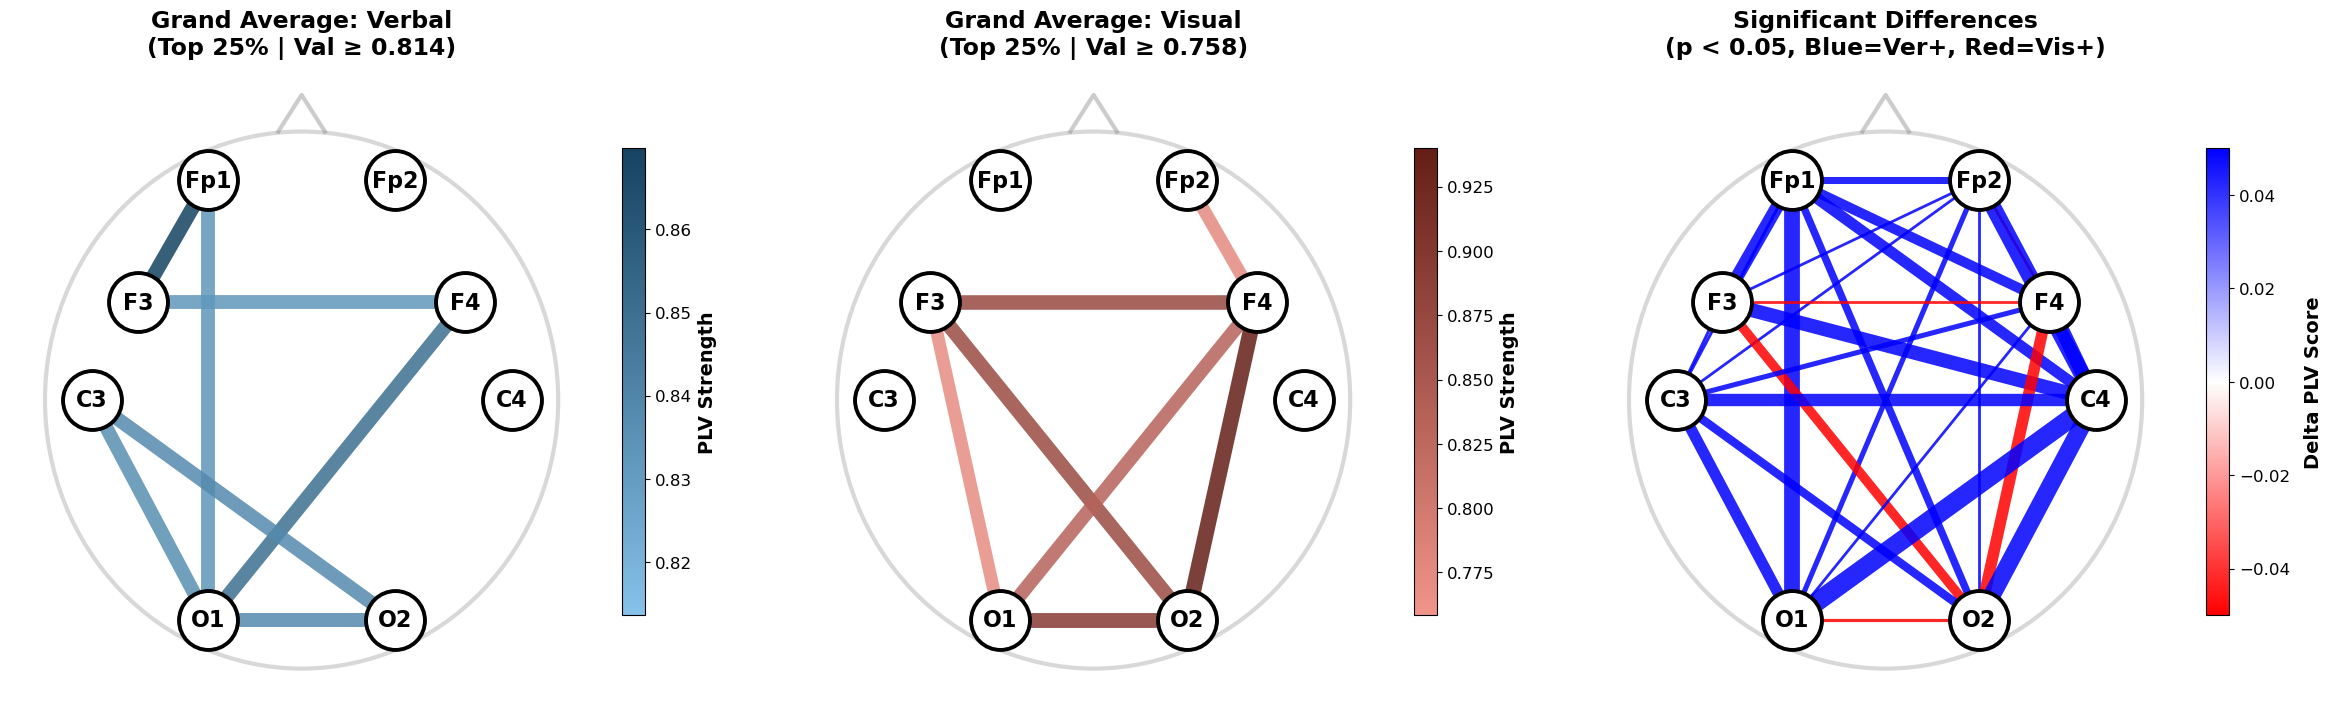

In [2]:
import matplotlib.cm as cm
from matplotlib.colors import LinearSegmentedColormap, Normalize
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from scipy.stats import ttest_ind

# 1. Load Data
file_input = "combined_fe_plv_vv.csv"
df = pd.read_csv(file_input)

# Penentuan Warna Kelas Utama
COLOR_VERBAL = "blue"
COLOR_VISUAL = "red"

# Definisi elektroda & posisi
electrodes = ["Fp1", "Fp2", "F3", "F4", "C3", "C4", "O1", "O2"]
pos = {
    "Fp1": (-0.4, 0.9),  "Fp2": (0.4, 0.9),
    "F3": (-0.7, 0.4),   "F4": (0.7, 0.4),
    "C3": (-0.9, 0.0),   "C4": (0.9, 0.0),
    "O1": (-0.4, -0.9),  "O2": (0.4, -0.9),
}

def get_stats_and_matrix(dataframe):
    feature_cols = [c for c in dataframe.columns if "-" in c]

    mat_verbal = np.zeros((8, 8))
    mat_visual = np.zeros((8, 8))
    p_values = np.ones((8, 8))

    df_verbal = dataframe[dataframe["label"].str.lower() == "verbal"]
    df_visual = dataframe[dataframe["label"].str.lower() == "visual"]

    mean_verbal = df_verbal[feature_cols].mean()
    mean_visual = df_visual[feature_cols].mean()

    for col in feature_cols:
        e1, e2 = col.split("-")
        i, j = electrodes.index(e1), electrodes.index(e2)

        mat_verbal[i, j] = mat_verbal[j, i] = mean_verbal[col]
        mat_visual[i, j] = mat_visual[j, i] = mean_visual[col]

        val_ver = df_verbal[col].dropna()
        val_vis = df_visual[col].dropna()
        if len(val_ver) > 0 and len(val_vis) > 0:
            _, p = ttest_ind(val_ver, val_vis)
            p_values[i, j] = p_values[j, i] = p

    return mat_verbal, mat_visual, p_values


# Perhitungan Statistik
mat_verbal, mat_visual, p_vals = get_stats_and_matrix(df)
delta_mat = mat_verbal - mat_visual

def draw_brain_net(
    ax,
    matrix,
    title,
    cmap_gradient=None,
    p_matrix=None,
    is_delta=False,
    c_ver=COLOR_VERBAL,
    c_vis=COLOR_VISUAL,
):
    G = nx.Graph()
    for e in electrodes:
        G.add_node(e)

    # Thresholding dinamis
    if is_delta:
        threshold = 0.001
        vmax = 0.05
    else:
        threshold = np.percentile(matrix[matrix > 0], 75)
        vmax = np.max(matrix)
        # Tambahkan informasi threshold ke dalam judul grafik
        title = f"{title}\n(Top 25% | Val \u2265 {threshold:.3f})"

    # Setup normalisasi warna (agar warna memetakan nilai PLV aktual)
    sm = None
    norm = None
    if not is_delta and cmap_gradient is not None:
        norm = Normalize(vmin=threshold, vmax=vmax)
        sm = plt.cm.ScalarMappable(cmap=cmap_gradient, norm=norm)

    for i in range(8):
        for j in range(i + 1, 8):
            val = matrix[i, j]
            if is_delta:
                is_sig = p_matrix[i, j] < 0.05 if p_matrix is not None else True
                if is_sig and np.abs(val) >= threshold:
                    color = c_ver if val > 0 else c_vis
                    G.add_edge(electrodes[i], electrodes[j], weight=val, color=color)
            else:
                if val >= threshold:
                    # Ambil warna dari ColorMap sesuai besaran nilainya
                    color = cmap_gradient(norm(val)) if norm else "black"
                    G.add_edge(electrodes[i], electrodes[j], weight=val, color=color)

    # Gambar Kontur Kepala (Lingkaran & Hidung)
    ax.add_patch(plt.Circle((0, 0), 1.1, color="grey", fill=False, alpha=0.3, lw=3))
    ax.plot([-0.1, 0, 0.1], [1.1, 1.25, 1.1], color="grey", alpha=0.4, lw=3)

    # 1. Gambar Node (Lingkaran Elektroda)
    nx.draw_networkx_nodes(
        G, pos, ax=ax, node_size=1800, node_color="white", edgecolors="black", linewidths=2.8
    )

    # 2. Gambar Label Elektroda
    nx.draw_networkx_labels(
        G, pos, ax=ax, font_size=16, font_weight="bold", font_family="sans-serif"
    )

    # 3. Gambar Garis Konektivitas dengan Transparansi
    if G.number_of_edges() > 0:
        base_w = 40 if is_delta else 12
        weights = [max(2.0, np.abs(G[u][v]["weight"]) * base_w) for u, v in G.edges()]
        colors = [G[u][v]["color"] for u, v in G.edges()]

        nx.draw_networkx_edges(
            G, pos, ax=ax, edge_color=colors, width=weights, alpha=0.85, node_size=1800
        )

    ax.set_title(title, fontsize=17, fontweight="bold", pad=12)
    ax.set_xlim(-1.25, 1.25)
    ax.set_ylim(-1.20, 1.35)
    ax.axis("off")
    
    return sm


# ==========================================
# PLOTTING UTAMA
# ==========================================
# Lebar figure diperbesar untuk mengakomodasi 3 colorbar
fig, axes = plt.subplots(1, 3, figsize=(24, 7.5))

# Membuat Custom Colormap (Warna muda ke tua agar garis terlemah tidak berwarna putih)
cmap_verbal = LinearSegmentedColormap.from_list("VerbalMap", ["#85c1e9", "#154360"]) 
cmap_visual = LinearSegmentedColormap.from_list("VisualMap", ["#f1948a", "#641e16"]) 

# 1. Panel Verbal
sm_ver = draw_brain_net(axes[0], mat_verbal, "Grand Average: Verbal", cmap_gradient=cmap_verbal)
cbar0 = fig.colorbar(sm_ver, ax=axes[0], shrink=0.75, pad=0.04)
cbar0.set_label("PLV Strength", fontsize=14, fontweight="bold")
cbar0.ax.tick_params(labelsize=12)

# 2. Panel Visual
sm_vis = draw_brain_net(axes[1], mat_visual, "Grand Average: Visual", cmap_gradient=cmap_visual)
cbar1 = fig.colorbar(sm_vis, ax=axes[1], shrink=0.75, pad=0.04)
cbar1.set_label("PLV Strength", fontsize=14, fontweight="bold")
cbar1.ax.tick_params(labelsize=12)

# 3. Panel Delta
draw_brain_net(
    axes[2], delta_mat, "Significant Differences\n(p < 0.05, Blue=Ver+, Red=Vis+)", 
    p_matrix=p_vals, is_delta=True
)

# Custom Colormap Merah -> Putih -> Biru untuk Delta
custom_cmap_delta = LinearSegmentedColormap.from_list("Vis_to_Ver", [COLOR_VISUAL, "white", COLOR_VERBAL])
sm_delta = plt.cm.ScalarMappable(cmap=custom_cmap_delta, norm=Normalize(vmin=-0.05, vmax=0.05))

cbar_delta = fig.colorbar(sm_delta, ax=axes[2], shrink=0.75, pad=0.04)
cbar_delta.set_label("Delta PLV Score", fontsize=14, fontweight="bold", labelpad=10)
cbar_delta.ax.tick_params(labelsize=12)

plt.subplots_adjust(left=0.02, right=0.98, wspace=0.1, top=0.88, bottom=0.05)
plt.show()

## Alpha Beta

### Alpha

In [2]:
import pandas as pd
import numpy as np
import os
from scipy.signal import hilbert

# ==========================================
# 1. KONFIGURASI & MAPPING CHANNEL
# ==========================================
CHANNEL_NAMES = {
    0: "Fp1", 1: "Fp2", 2: "F3", 3: "F4",
    4: "C3", 5: "C4", 6: "O1", 7: "O2"
}

def get_plv_feature_names(channel_map):
    names = []
    n_ch = len(channel_map)
    for i in range(n_ch):
        for j in range(i + 1, n_ch):
            names.append(f"{channel_map[i]}-{channel_map[j]}")
    return names

# Generate nama kolom fitur satu kali di awal
PLV_FEATURE_NAMES = get_plv_feature_names(CHANNEL_NAMES)

# ==========================================
# 2. FUNGSI INTI KOMPUTASI PLV
# ==========================================
def compute_plv_window(window_data):
    """
    Menghitung sinkronisasi fase antar channel menggunakan Hilbert Transform.
    window_data : np.array [n_channels, n_samples]
    """
    window_data = np.asarray(window_data, dtype=float)
    n_ch, _ = window_data.shape

    # Transformasi Hilbert untuk mendapatkan fase instan
    analytic = hilbert(window_data, axis=1)
    phase = np.angle(analytic)

    plv_vals = []
    for i in range(n_ch):
        for j in range(i+1, n_ch):
            # Rumus PLV: |1/N * sum(exp(i * (phase_i - phase_j)))|
            diff = phase[i] - phase[j]
            plv = np.abs(np.mean(np.exp(1j * diff)))
            plv_vals.append(plv)

    return np.array(plv_vals, dtype=np.float32)

# ==========================================
# 3. PROSES EKSTRAKSI PER FILE (MODIFIKASI AR)
# ==========================================
def process_eeg_plv(input_folder, output_folder):
    if not os.path.exists(output_folder):
        os.makedirs(output_folder)

    files = sorted([f for f in os.listdir(input_folder) if f.endswith(".csv")])
    print(f"🚀 Memulai ekstraksi PLV (verbal-visual). Ditemukan {len(files)} file.")

    # Kolom datapoint (asumsi 250Hz per window)
    dp_cols = [f"datapoint{i}" for i in range(1, 251)]

    for i, fname in enumerate(files, start=1):
        # DETEKSI LABEL: Mengubah logika untuk mencari kata 'verbal' atau 'visual'
        if "verbal" in fname.lower():
            current_label = "verbal"
        elif "visual" in fname.lower():
            current_label = "visual"
        else:
            current_label = "unknown" # Fallback jika nama file tidak standar
            
        csv_path = os.path.join(input_folder, fname)
        
        df = pd.read_csv(csv_path)
        rows_out = []

        # Grouping berdasarkan Trial (nomor) dan Window
        grouped = df.groupby(["nomor", "window"])

        for (trial_id, window_id), g in grouped:
            if g.shape[0] != 8:
                continue  # Pastikan 8 channel lengkap

            # Urutkan berdasarkan channel agar mapping elektroda konsisten
            g = g.sort_values("channel")
            window_data = g[dp_cols].values 

            # Hitung PLV
            plv_feat = compute_plv_window(window_data)

            # Susun baris hasil
            res_row = {
                "subject": i,
                "trial": trial_id,
                "window": window_id,
                "label": current_label
            }
            
            # Tambahkan 28 fitur PLV (konektivitas antar elektroda)
            for fname_feat, val in zip(PLV_FEATURE_NAMES, plv_feat):
                res_row[fname_feat] = val
            
            rows_out.append(res_row)

        # Simpan per subjek
        df_final = pd.DataFrame(rows_out)
        out_filename = f"subject_{i:02d}_PLV_AR.csv"
        df_final.to_csv(os.path.join(output_folder, out_filename), index=False)
        
        print(f"✅ Selesai: {out_filename} | Total Window: {len(df_final)} | Label: {current_label}")

# ==========================================
# 4. EKSEKUSI
# ==========================================
# Sesuaikan nama folder dengan struktur direktori Anda
INPUT_PATH = "/Users/wigabaihaqi/Library/CloudStorage/GoogleDrive-wiga@amikompurwokerto.ac.id/My Drive/Doktor Teknik Elektro/Semester II/Eksperimen/Vektor PLV/dataset_verbal-visual/beta"      
OUTPUT_PATH = "features-plv-vv-beta"

process_eeg_plv(INPUT_PATH, OUTPUT_PATH)


🚀 Memulai ekstraksi PLV (verbal-visual). Ditemukan 10 file.
✅ Selesai: subject_01_PLV_AR.csv | Total Window: 300 | Label: verbal
✅ Selesai: subject_02_PLV_AR.csv | Total Window: 300 | Label: verbal
✅ Selesai: subject_03_PLV_AR.csv | Total Window: 300 | Label: verbal
✅ Selesai: subject_04_PLV_AR.csv | Total Window: 300 | Label: verbal
✅ Selesai: subject_05_PLV_AR.csv | Total Window: 300 | Label: verbal
✅ Selesai: subject_06_PLV_AR.csv | Total Window: 300 | Label: visual
✅ Selesai: subject_07_PLV_AR.csv | Total Window: 300 | Label: visual
✅ Selesai: subject_08_PLV_AR.csv | Total Window: 300 | Label: visual
✅ Selesai: subject_09_PLV_AR.csv | Total Window: 300 | Label: visual
✅ Selesai: subject_10_PLV_AR.csv | Total Window: 300 | Label: visual


/Users/wigabaihaqi/anaconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
/var/folders/24/nr_zy5615zv391x46lkwdw780000gn/T/ipykernel_4605/3207065500.py:88: DeprecationWarning: `alltrue` is deprecated as of NumPy 1.25.0, and will be removed in NumPy 2.0. Please use `all` instead.
  nx.draw_networkx_edges(G, pos, ax=ax, edge_color=colors, width=weights, alpha=0.5)


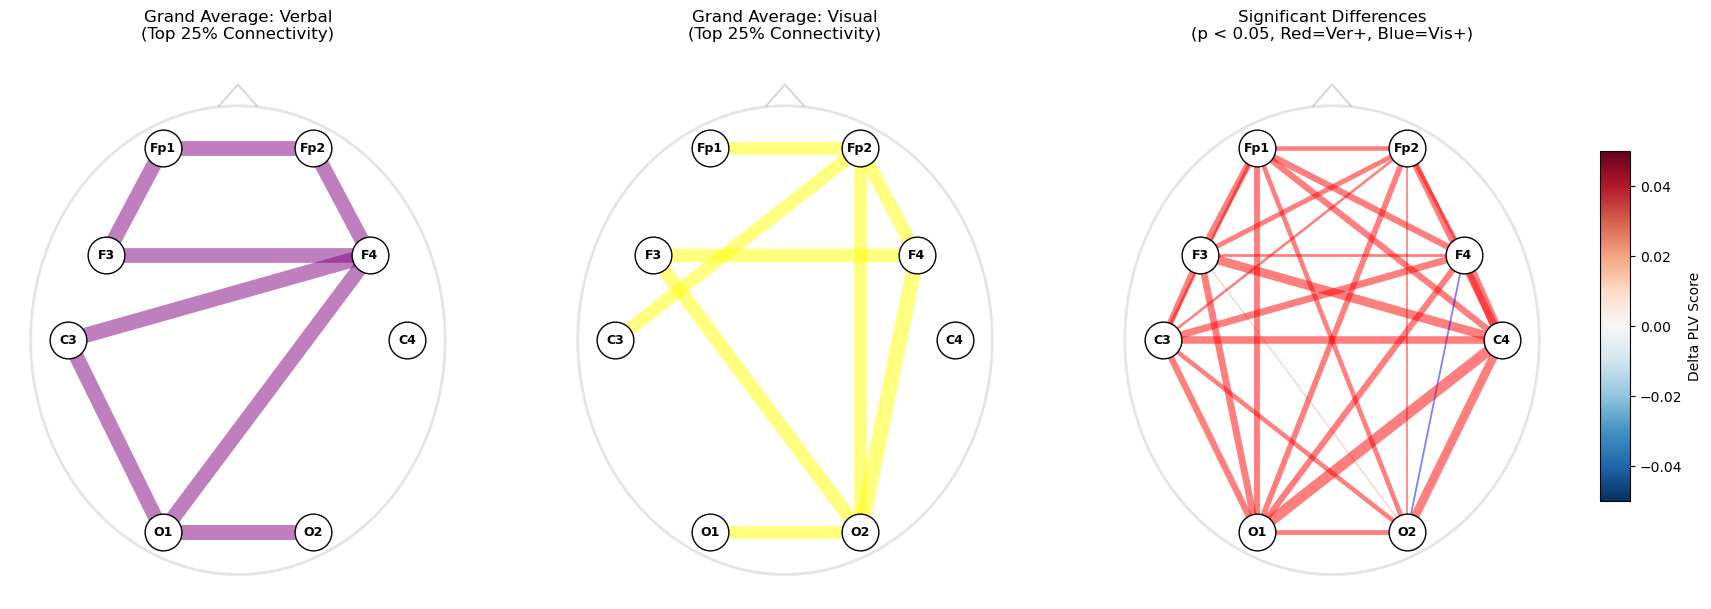

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from scipy.stats import ttest_ind
import matplotlib.cm as cm

# 1. Load Data
file_input = "gabungan-FE-PLV-VV-alpha.csv"
df = pd.read_csv(file_input)

# Definisi elektroda & posisi
electrodes = ['Fp1', 'Fp2', 'F3', 'F4', 'C3', 'C4', 'O1', 'O2']
pos = {
    'Fp1': (-0.4, 0.9), 'Fp2': (0.4, 0.9),
    'F3': (-0.7, 0.4),  'F4': (0.7, 0.4),
    'C3': (-0.9, 0.0),  'C4': (0.9, 0.0),
    'O1': (-0.4, -0.9), 'O2': (0.4, -0.9)
}

def get_stats_and_matrix(dataframe):
    feature_cols = [c for c in dataframe.columns if '-' in c]
    
    # Hitung rata-rata
    mat_verbal = np.zeros((8, 8))
    mat_refl = np.zeros((8, 8))
    p_values = np.ones((8, 8)) # Untuk t-test
    
    df_verbal = dataframe[dataframe['label'] == 'verbal']
    df_refl = dataframe[dataframe['label'] == 'visual']
    
    mean_verbal = df_verbal[feature_cols].mean()
    mean_refl = df_refl[feature_cols].mean()
    
    for col in feature_cols:
        e1, e2 = col.split('-')
        i, j = electrodes.index(e1), electrodes.index(e2)
        
        # Isi matriks rata-rata
        mat_verbal[i, j] = mat_verbal[j, i] = mean_verbal[col]
        mat_refl[i, j] = mat_refl[j, i] = mean_refl[col]
        
        # Hitung T-Test untuk setiap jalur
        _, p = ttest_ind(df_verbal[col], df_refl[col])
        p_values[i, j] = p_values[j, i] = p
        
    return mat_verbal, mat_refl, p_values

# Jalankan perhitungan statistik
mat_verbal, mat_visual, p_vals = get_stats_and_matrix(df)
delta_mat = mat_verbal - mat_visual

def draw_brain_net(ax, matrix, title, cmap_color, p_matrix=None, is_delta=False):
    G = nx.Graph()
    for e in electrodes: G.add_node(e)
    
    # Thresholding
    if is_delta:
        # Hanya tampilkan yang signifikan secara statistik (p < 0.05)
        # DAN masuk dalam top 20% perbedaan terbesar
        threshold = np.percentile(np.abs(matrix), 80)
    else:
        threshold = np.percentile(matrix, 75)

    for i in range(8):
        for j in range(i + 1, 8):
            val = matrix[i, j]
            # Logika filter
            if is_delta:
                if p_matrix[i, j] < 0.05 and np.abs(val) > 0.01: # Signifikan & tidak terlalu kecil
                    color = 'red' if val > 0 else 'blue'
                    G.add_edge(electrodes[i], electrodes[j], weight=val, color=color)
            else:
                if val >= threshold:
                    G.add_edge(electrodes[i], electrodes[j], weight=val, color=cmap_color)

    # Gambar Kepala
    ax.add_patch(plt.Circle((0, 0), 1.1, color='grey', fill=False, alpha=0.2, lw=2))
    ax.plot([-0.1, 0, 0.1], [1.1, 1.2, 1.1], color='grey', alpha=0.3) 

    if G.number_of_edges() > 0:
        # Normalisasi weight agar visualisasi konsisten
        # Scaling: Delta dikali lebih besar agar perbedaan terlihat
        base_w = 25 if is_delta else 12 
        weights = [np.abs(G[u][v]['weight']) * base_w for u, v in G.edges()]
        colors = [G[u][v]['color'] for u, v in G.edges()]
        
        nx.draw_networkx_edges(G, pos, ax=ax, edge_color=colors, width=weights, alpha=0.5)
    
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=700, node_color='white', edgecolors='black', linewidths=1)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=9, font_weight='bold')
    
    ax.set_title(title, fontsize=12, pad=15)
    ax.axis('off')

# Plotting
fig, axes = plt.subplots(1, 3, figsize=(20, 7))

draw_brain_net(axes[0], mat_verbal, "Grand Average: Verbal\n(Top 25% Connectivity)", "purple")
draw_brain_net(axes[1], mat_visual, "Grand Average: Visual\n(Top 25% Connectivity)", "yellow")
draw_brain_net(axes[2], delta_mat, "Significant Differences\n(p < 0.05, Red=Ver+, Blue=Vis+)", None, p_matrix=p_vals, is_delta=True)

# Tambahkan Colorbar untuk Differential Plot
sm = plt.cm.ScalarMappable(cmap=plt.cm.RdBu_r, norm=plt.Normalize(vmin=-0.05, vmax=0.05))
cbar_ax = fig.add_axes([0.92, 0.25, 0.015, 0.5]) # [left, bottom, width, height]
fig.colorbar(sm, cax=cbar_ax, label='Delta PLV Score')

plt.subplots_adjust(right=0.9)
plt.show()

/var/folders/24/nr_zy5615zv391x46lkwdw780000gn/T/ipykernel_4605/2887907034.py:88: DeprecationWarning: `alltrue` is deprecated as of NumPy 1.25.0, and will be removed in NumPy 2.0. Please use `all` instead.
  nx.draw_networkx_edges(G, pos, ax=ax, edge_color=colors, width=weights, alpha=0.5)


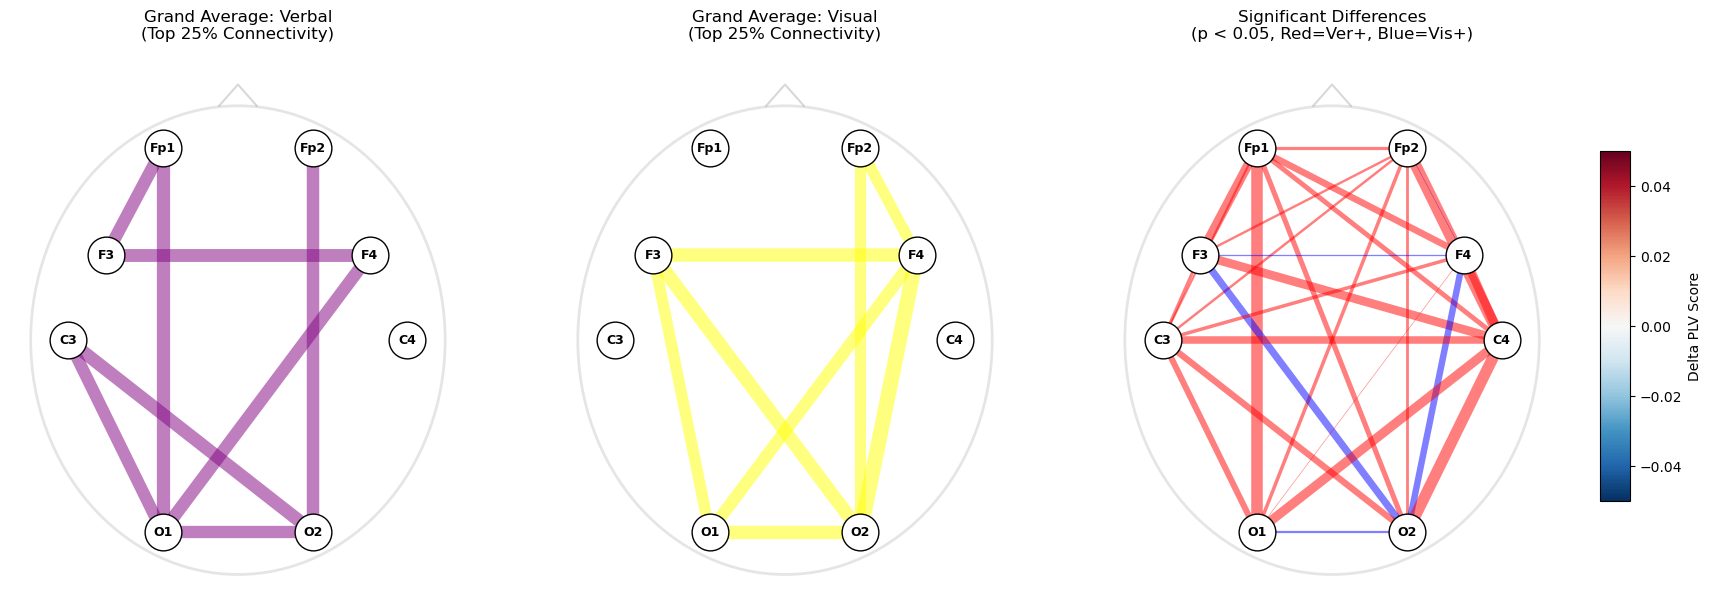

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from scipy.stats import ttest_ind
import matplotlib.cm as cm

# 1. Load Data
file_input = "gabungan-FE-PLV-VV-beta.csv"
df = pd.read_csv(file_input)

# Definisi elektroda & posisi
electrodes = ['Fp1', 'Fp2', 'F3', 'F4', 'C3', 'C4', 'O1', 'O2']
pos = {
    'Fp1': (-0.4, 0.9), 'Fp2': (0.4, 0.9),
    'F3': (-0.7, 0.4),  'F4': (0.7, 0.4),
    'C3': (-0.9, 0.0),  'C4': (0.9, 0.0),
    'O1': (-0.4, -0.9), 'O2': (0.4, -0.9)
}

def get_stats_and_matrix(dataframe):
    feature_cols = [c for c in dataframe.columns if '-' in c]
    
    # Hitung rata-rata
    mat_verbal = np.zeros((8, 8))
    mat_refl = np.zeros((8, 8))
    p_values = np.ones((8, 8)) # Untuk t-test
    
    df_verbal = dataframe[dataframe['label'] == 'verbal']
    df_refl = dataframe[dataframe['label'] == 'visual']
    
    mean_verbal = df_verbal[feature_cols].mean()
    mean_refl = df_refl[feature_cols].mean()
    
    for col in feature_cols:
        e1, e2 = col.split('-')
        i, j = electrodes.index(e1), electrodes.index(e2)
        
        # Isi matriks rata-rata
        mat_verbal[i, j] = mat_verbal[j, i] = mean_verbal[col]
        mat_refl[i, j] = mat_refl[j, i] = mean_refl[col]
        
        # Hitung T-Test untuk setiap jalur
        _, p = ttest_ind(df_verbal[col], df_refl[col])
        p_values[i, j] = p_values[j, i] = p
        
    return mat_verbal, mat_refl, p_values

# Jalankan perhitungan statistik
mat_verbal, mat_visual, p_vals = get_stats_and_matrix(df)
delta_mat = mat_verbal - mat_visual

def draw_brain_net(ax, matrix, title, cmap_color, p_matrix=None, is_delta=False):
    G = nx.Graph()
    for e in electrodes: G.add_node(e)
    
    # Thresholding
    if is_delta:
        # Hanya tampilkan yang signifikan secara statistik (p < 0.05)
        # DAN masuk dalam top 20% perbedaan terbesar
        threshold = np.percentile(np.abs(matrix), 80)
    else:
        threshold = np.percentile(matrix, 75)

    for i in range(8):
        for j in range(i + 1, 8):
            val = matrix[i, j]
            # Logika filter
            if is_delta:
                if p_matrix[i, j] < 0.05 and np.abs(val) > 0.01: # Signifikan & tidak terlalu kecil
                    color = 'red' if val > 0 else 'blue'
                    G.add_edge(electrodes[i], electrodes[j], weight=val, color=color)
            else:
                if val >= threshold:
                    G.add_edge(electrodes[i], electrodes[j], weight=val, color=cmap_color)

    # Gambar Kepala
    ax.add_patch(plt.Circle((0, 0), 1.1, color='grey', fill=False, alpha=0.2, lw=2))
    ax.plot([-0.1, 0, 0.1], [1.1, 1.2, 1.1], color='grey', alpha=0.3) 

    if G.number_of_edges() > 0:
        # Normalisasi weight agar visualisasi konsisten
        # Scaling: Delta dikali lebih besar agar perbedaan terlihat
        base_w = 25 if is_delta else 12 
        weights = [np.abs(G[u][v]['weight']) * base_w for u, v in G.edges()]
        colors = [G[u][v]['color'] for u, v in G.edges()]
        
        nx.draw_networkx_edges(G, pos, ax=ax, edge_color=colors, width=weights, alpha=0.5)
    
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=700, node_color='white', edgecolors='black', linewidths=1)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=9, font_weight='bold')
    
    ax.set_title(title, fontsize=12, pad=15)
    ax.axis('off')

# Plotting
fig, axes = plt.subplots(1, 3, figsize=(20, 7))

draw_brain_net(axes[0], mat_verbal, "Grand Average: Verbal\n(Top 25% Connectivity)", "purple")
draw_brain_net(axes[1], mat_visual, "Grand Average: Visual\n(Top 25% Connectivity)", "yellow")
draw_brain_net(axes[2], delta_mat, "Significant Differences\n(p < 0.05, Red=Ver+, Blue=Vis+)", None, p_matrix=p_vals, is_delta=True)

# Tambahkan Colorbar untuk Differential Plot
sm = plt.cm.ScalarMappable(cmap=plt.cm.RdBu_r, norm=plt.Normalize(vmin=-0.05, vmax=0.05))
cbar_ax = fig.add_axes([0.92, 0.25, 0.015, 0.5]) # [left, bottom, width, height]
fig.colorbar(sm, cax=cbar_ax, label='Delta PLV Score')

plt.subplots_adjust(right=0.9)
plt.show()

### Alpha

In [1]:
import pandas as pd
import numpy as np
import os
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix

# 1. Load Data
file_input = "gabungan-FE-PLV-VV-alpha.csv"

if not os.path.exists(file_input):
    print(f"File {file_input} tidak ditemukan!")
else:
    df = pd.read_csv(file_input)
    
    # 2. Persiapan
    df["y"] = df["label"].map({"verbal": 0, "visual": 1})
    feature_cols = [c for c in df.columns if '-' in c]
    subjects = df["subject"].unique()
    all_test_predictions = []

    # 3. Loop LOSO
    for test_subj in subjects:
        df_train = df[df["subject"] != test_subj]
        df_test  = df[df["subject"] == test_subj].copy()
        
        X_train, y_train = df_train[feature_cols].values, df_train["y"].values
        X_test, y_test   = df_test[feature_cols].values, df_test["y"].values
        
        clf = SVC(kernel="rbf", C=1.0, gamma="scale", class_weight='balanced')
        clf.fit(X_train, y_train)
        
        df_test["y_pred"] = clf.predict(X_test)
        all_test_predictions.append(df_test)

    df_final_results = pd.concat(all_test_predictions)

    # 4. Fungsi Compute Trial Voting (Mekanisme Inti)
    def compute_trial_results(df_res):
        rows = []
        for (subj, trial), g in df_res.groupby(["subject", "trial"]):
            true_label = g["label"].iloc[0]
            act_votes = np.sum(g["y_pred"] == 0)
            refl_votes = np.sum(g["y_pred"] == 1)
            
            # Mekanisme Majority Voting per Trial
            predicted_label = "verbal" if act_votes > refl_votes else "visual"
            
            rows.append({
                "subject": subj, 
                "trial": trial, 
                "True_Label": true_label,
                "Predicted": predicted_label,
                "Act_Votes": act_votes,
                "Refl_Votes": refl_votes
            })
        return pd.DataFrame(rows)

    trial_results_df = compute_trial_results(df_final_results)

    # 5. MODIFIKASI: ANALISIS PER SUBJEK BERDASARKAN VOTING
    print("\n" + "="*95)
    print(" INDIVIDUAL SUBJECT ANALYSIS (BASED ON MAJORITY VOTING RESULTS) ")
    print("="*95)
    
    subject_analysis = []
    for subj in subjects:
        # Ambil hasil voting trial untuk subjek ini
        subj_trials = trial_results_df[trial_results_df["subject"] == subj]
        total_trials = len(subj_trials)
        
        # Hitung berapa trial yang benar
        correct_trials = np.sum(subj_trials["True_Label"] == subj_trials["Predicted"])
        accuracy_subj = (correct_trials / total_trials) * 100
        
        # Hitung sebaran voting akhir
        count_pred_verbal = np.sum(subj_trials["Predicted"] == "verbal")
        count_pred_refl = np.sum(subj_trials["Predicted"] == "visual")
        
        # Penentuan Error Type berdasarkan konsistensi voting
        true_label = subj_trials["True_Label"].iloc[0]
        error_pattern = "Correct"
        
        if accuracy_subj < 50.0:
            if true_label == "verbal" and count_pred_refl > (total_trials * 0.8):
                error_pattern = "Systematic Bias to Reflective"
            elif true_label == "visual" and count_pred_verbal > (total_trials * 0.8):
                error_pattern = "Systematic Bias to Active"
            else:
                error_pattern = "Ambiguous/Mixed"

        subject_analysis.append({
            "Subject": subj,
            "True_Label": true_label,
            "Subject_Acc": f"{accuracy_subj:.2f}%",
            "Votes_active": count_pred_verbal,
            "Votes_Refl": count_pred_refl,
            "Error_Type": error_pattern
        })

    analysis_df = pd.DataFrame(subject_analysis)
    print(analysis_df.to_string(index=False))

    # Simpan hasil
    #analysis_df.to_csv("analisis_voting_per_subjek_ar.csv", index=False)
    #print("\n[INFO] Analisis berbasis voting disimpan ke 'analisis_voting_per_subjek_ar.csv'")

/Users/wigabaihaqi/anaconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (



 INDIVIDUAL SUBJECT ANALYSIS (BASED ON MAJORITY VOTING RESULTS) 
 Subject True_Label Subject_Acc  Votes_active  Votes_Refl                    Error_Type
       1     verbal      25.00%             5          15               Ambiguous/Mixed
       2     verbal     100.00%            20           0                       Correct
       3     verbal      90.00%            18           2                       Correct
       4     verbal     100.00%            20           0                       Correct
       5     verbal      10.00%             2          18 Systematic Bias to Reflective
       6     visual      85.00%             3          17                       Correct
       7     visual      75.00%             5          15                       Correct
       8     visual     100.00%             0          20                       Correct
       9     visual      60.00%             8          12                       Correct
      10     visual     100.00%             0         

In [2]:
import pandas as pd
import numpy as np
import os
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix

# 1. Load Data
file_input = "gabungan-FE-PLV-VV-beta.csv"

if not os.path.exists(file_input):
    print(f"File {file_input} tidak ditemukan!")
else:
    df = pd.read_csv(file_input)
    
    # 2. Persiapan
    df["y"] = df["label"].map({"verbal": 0, "visual": 1})
    feature_cols = [c for c in df.columns if '-' in c]
    subjects = df["subject"].unique()
    all_test_predictions = []

    # 3. Loop LOSO
    for test_subj in subjects:
        df_train = df[df["subject"] != test_subj]
        df_test  = df[df["subject"] == test_subj].copy()
        
        X_train, y_train = df_train[feature_cols].values, df_train["y"].values
        X_test, y_test   = df_test[feature_cols].values, df_test["y"].values
        
        clf = SVC(kernel="rbf", C=1.0, gamma="scale", class_weight='balanced')
        clf.fit(X_train, y_train)
        
        df_test["y_pred"] = clf.predict(X_test)
        all_test_predictions.append(df_test)

    df_final_results = pd.concat(all_test_predictions)

    # 4. Fungsi Compute Trial Voting (Mekanisme Inti)
    def compute_trial_results(df_res):
        rows = []
        for (subj, trial), g in df_res.groupby(["subject", "trial"]):
            true_label = g["label"].iloc[0]
            act_votes = np.sum(g["y_pred"] == 0)
            refl_votes = np.sum(g["y_pred"] == 1)
            
            # Mekanisme Majority Voting per Trial
            predicted_label = "verbal" if act_votes > refl_votes else "visual"
            
            rows.append({
                "subject": subj, 
                "trial": trial, 
                "True_Label": true_label,
                "Predicted": predicted_label,
                "Act_Votes": act_votes,
                "Refl_Votes": refl_votes
            })
        return pd.DataFrame(rows)

    trial_results_df = compute_trial_results(df_final_results)

    # 5. MODIFIKASI: ANALISIS PER SUBJEK BERDASARKAN VOTING
    print("\n" + "="*95)
    print(" INDIVIDUAL SUBJECT ANALYSIS (BASED ON MAJORITY VOTING RESULTS) ")
    print("="*95)
    
    subject_analysis = []
    for subj in subjects:
        # Ambil hasil voting trial untuk subjek ini
        subj_trials = trial_results_df[trial_results_df["subject"] == subj]
        total_trials = len(subj_trials)
        
        # Hitung berapa trial yang benar
        correct_trials = np.sum(subj_trials["True_Label"] == subj_trials["Predicted"])
        accuracy_subj = (correct_trials / total_trials) * 100
        
        # Hitung sebaran voting akhir
        count_pred_verbal = np.sum(subj_trials["Predicted"] == "verbal")
        count_pred_refl = np.sum(subj_trials["Predicted"] == "visual")
        
        # Penentuan Error Type berdasarkan konsistensi voting
        true_label = subj_trials["True_Label"].iloc[0]
        error_pattern = "Correct"
        
        if accuracy_subj < 50.0:
            if true_label == "verbal" and count_pred_refl > (total_trials * 0.8):
                error_pattern = "Systematic Bias to Reflective"
            elif true_label == "visual" and count_pred_verbal > (total_trials * 0.8):
                error_pattern = "Systematic Bias to Active"
            else:
                error_pattern = "Ambiguous/Mixed"

        subject_analysis.append({
            "Subject": subj,
            "True_Label": true_label,
            "Subject_Acc": f"{accuracy_subj:.2f}%",
            "Votes_active": count_pred_verbal,
            "Votes_Refl": count_pred_refl,
            "Error_Type": error_pattern
        })

    analysis_df = pd.DataFrame(subject_analysis)
    print(analysis_df.to_string(index=False))

    # Simpan hasil
    #analysis_df.to_csv("analisis_voting_per_subjek_ar.csv", index=False)
    #print("\n[INFO] Analisis berbasis voting disimpan ke 'analisis_voting_per_subjek_ar.csv'")


 INDIVIDUAL SUBJECT ANALYSIS (BASED ON MAJORITY VOTING RESULTS) 
 Subject True_Label Subject_Acc  Votes_active  Votes_Refl                    Error_Type
       1     verbal      95.00%            19           1                       Correct
       2     verbal       0.00%             0          20 Systematic Bias to Reflective
       3     verbal      90.00%            18           2                       Correct
       4     verbal       0.00%             0          20 Systematic Bias to Reflective
       5     verbal      10.00%             2          18 Systematic Bias to Reflective
       6     visual      45.00%            11           9               Ambiguous/Mixed
       7     visual     100.00%             0          20                       Correct
       8     visual     100.00%             0          20                       Correct
       9     visual      30.00%            14           6               Ambiguous/Mixed
      10     visual     100.00%             0         

In [4]:
import pandas as pd
import numpy as np
import os
import warnings
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.preprocessing import StandardScaler

# Menghilangkan peringatan jika diperlukan
warnings.filterwarnings('ignore')

# 1. Load Data
file_input = "gabungan-FE-PLV-VV-beta.csv"

if not os.path.exists(file_input):
    print(f"File {file_input} tidak ditemukan!")
else:
    df = pd.read_csv(file_input)
    
    # 2. Persiapan
    df["y"] = df["label"].map({"verbal": 0, "visual": 1})
    feature_cols = [c for c in df.columns if '-' in c]
    subjects = df["subject"].unique()
    all_test_predictions = []

    # 3. Loop LOSO dengan Normalisasi Subject-Specific
    for test_subj in subjects:
        # Pisahkan train dan test berdasarkan subjek
        df_train = df[df["subject"] != test_subj].copy()
        df_test  = df[df["subject"] == test_subj].copy()
        
        # --- TAHAP NORMALISASI (Subject-Specific) ---
        # 1. Normalisasi per subjek dalam Train Set
        for s in df_train["subject"].unique():
            mask = df_train["subject"] == s
            scaler_tr = StandardScaler()
            df_train.loc[mask, feature_cols] = scaler_tr.fit_transform(df_train.loc[mask, feature_cols])
        
        # 2. Normalisasi independen untuk Test Set (Subjek Uji)
        scaler_te = StandardScaler()
        df_test.loc[:, feature_cols] = scaler_te.fit_transform(df_test[feature_cols])

        # Ekstrak fitur dan label yang sudah dinormalisasi
        X_train_scaled = df_train[feature_cols].values
        y_train = df_train["y"].values
        
        X_test_scaled = df_test[feature_cols].values
        y_test = df_test["y"].values
        
        # 4. Inisialisasi & Fit SVM menggunakan data yang sudah dinormalisasi
        clf = SVC(kernel="rbf", C=1.0, gamma="scale", class_weight='balanced', random_state=42)
        clf.fit(X_train_scaled, y_train)
        
        # Prediksi menggunakan data test yang dinormalisasi
        df_test["y_pred"] = clf.predict(X_test_scaled)
        all_test_predictions.append(df_test)

    df_final_results = pd.concat(all_test_predictions)

    # 4. Fungsi Compute Trial Voting (Mekanisme Inti)
    def compute_trial_results(df_res):
        rows = []
        for (subj, trial), g in df_res.groupby(["subject", "trial"]):
            true_label = g["label"].iloc[0]
            verbal_votes = np.sum(g["y_pred"] == 0)
            visual_votes = np.sum(g["y_pred"] == 1)
            
            # Mekanisme Majority Voting per Trial
            predicted_label = "verbal" if verbal_votes > visual_votes else "visual"
            
            rows.append({
                "subject": subj, 
                "trial": trial, 
                "True_Label": true_label,
                "Predicted": predicted_label,
                "Verbal_Votes": verbal_votes,
                "Visual_Votes": visual_votes
            })
        return pd.DataFrame(rows)

    trial_results_df = compute_trial_results(df_final_results)

    # 5. MODIFIKASI: ANALISIS PER SUBJEK BERDASARKAN VOTING
    print("\n" + "="*95)
    print(" INDIVIDUAL SUBJECT ANALYSIS (BASED ON MAJORITY VOTING RESULTS) WITH NORMALIZATION ")
    print("="*95)
    
    subject_analysis = []
    for subj in subjects:
        # Ambil hasil voting trial untuk subjek ini
        subj_trials = trial_results_df[trial_results_df["subject"] == subj]
        total_trials = len(subj_trials)
        
        # Hitung berapa trial yang benar
        correct_trials = np.sum(subj_trials["True_Label"] == subj_trials["Predicted"])
        accuracy_subj = (correct_trials / total_trials) * 100
        
        # Hitung sebaran voting akhir
        count_pred_verbal = np.sum(subj_trials["Predicted"] == "verbal")
        count_pred_visual = np.sum(subj_trials["Predicted"] == "visual")
        
        # Penentuan Error Type berdasarkan konsistensi voting
        true_label = subj_trials["True_Label"].iloc[0]
        error_pattern = "Correct"
        
        if accuracy_subj < 50.0:
            if true_label == "verbal" and count_pred_visual > (total_trials * 0.8):
                error_pattern = "Systematic Bias to Visual"
            elif true_label == "visual" and count_pred_verbal > (total_trials * 0.8):
                error_pattern = "Systematic Bias to Verbal"
            else:
                error_pattern = "Ambiguous/Mixed"

        subject_analysis.append({
            "Subject": subj,
            "True_Label": true_label,
            "Subject_Acc": f"{accuracy_subj:.2f}%",
            "Votes_Verbal": count_pred_verbal,
            "Votes_Visual": count_pred_visual,
            "Error_Type": error_pattern
        })

    analysis_df = pd.DataFrame(subject_analysis)
    print(analysis_df.to_string(index=False))

    # Simpan hasil (Opsional jika ingin diaktifkan)
    #analysis_df.to_csv("analisis_voting_per_subjek_vv_beta_norm.csv", index=False)
    #print("\n[INFO] Analisis berbasis voting disimpan ke 'analisis_voting_per_subjek_vv_beta_norm.csv'")


 INDIVIDUAL SUBJECT ANALYSIS (BASED ON MAJORITY VOTING RESULTS) WITH NORMALIZATION 
 Subject True_Label Subject_Acc  Votes_Verbal  Votes_Visual                Error_Type
       1     verbal      20.00%             4            16           Ambiguous/Mixed
       2     verbal     100.00%            20             0                   Correct
       3     verbal      85.00%            17             3                   Correct
       4     verbal     100.00%            20             0                   Correct
       5     verbal      10.00%             2            18 Systematic Bias to Visual
       6     visual      90.00%             2            18                   Correct
       7     visual      80.00%             4            16                   Correct
       8     visual       0.00%            20             0 Systematic Bias to Verbal
       9     visual      30.00%            14             6           Ambiguous/Mixed
      10     visual      80.00%             4          